## Chapter 4 - Estimating Price Response

### Exercise 2:

Fit a logistic model to the test data in Table 4.3 using Price, Weekend, and Potential 
Demand as explanatory variables.

a. What are the coefficients for each explanatory variable?

b. Calculate RMSE, MAPE, and weighted MAPE for the logistic model on the test 
data in Table 4.3. How does the fit of this model compare to the models estimated in the text and the model estimated in Exercise 1?

---

#### Summary

**Process:** fit the logit conversion-rate model $\rho(p, w) = \frac{e^{a - bp + cw}}{1 + e^{a - bp + cw}}$ on the training set, regressing the log odds of $r = \text{sales} / \text{potential}$ on Price and Weekend. Then predict test sales as $D \cdot \rho(p, w)$ and compute RMSE, MAPE and weighted MAPE.

**(a)** The coefficients were found to be $a = 36.40$, Price $= -5.22$ ($b = 5.22$), Weekend $c = 0.157$. Potential demand enters as a multiplier, with no coefficient.

**(b)** The test set metrics were found to be RMSE = 3.46, MAPE = 0.19, weighted MAPE = 0.12.

**Conclusion:** a much better fit than the text and Exercise 1 models. The gain comes from potential demand; Weekend adds little.

---

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

The formula for the logit model is (Equation 4.5)

$$\rho(p) = \frac{e^{a - bp}}{1 + e^{a - bp}}$$

where $\rho$ is the conversion rate (the fraction of potential demand that buys) and $p$ is the price.

Potential demand $D$ is not a regressor. It multiplies the conversion rate to give demand (Section 4.2.2):

$$d(p) = D \cdot \rho(p)$$

To estimate the parameters, we compute the observed conversion rate $\hat{r}_t = \hat{d}_t / \hat{D}_t$ for each day of the training set and take its log odds. This makes the model linear in the parameters (Equation 4.7):

$$\ln\left(\frac{\hat{r}_t}{1 - \hat{r}_t}\right) = a - b\,p_t$$

To include Weekend ($w_t = 1$ on weekends, $0$ otherwise), we add it to the linear part:

$$\ln\left(\frac{\hat{r}_t}{1 - \hat{r}_t}\right) = a - b\,p_t + c\,w_t$$

so we can fit $a$, $b$ and $c$ with an ordinary linear regression. Undoing the log odds, Weekend ends up in the exponent of the logit:

$$\rho(p, w) = \frac{e^{a - bp + cw}}{1 + e^{a - bp + cw}}, \qquad d(p, w) = D \cdot \rho(p, w)$$

On the test set, we predict the log odds, convert them back to $\rho$ with this function, and multiply by the test day's potential demand to get predicted sales.

In [29]:
# Importing the training and test datasets as pandas DataFrames
train_set = pd.read_csv("table4.2.csv")
test_set = pd.read_csv("table4.3.csv")

# Displaying the first 10 rows of the training and test datasets for verification
print("Number of rows and columns:", train_set.shape)
print(train_set.head(10))
print("Number of rows and columns:", test_set.shape)
print(test_set.head(10))

Number of rows and columns: (42, 5)
   day  price  sales  weekend  potential
0    1   6.45     49        1         52
1    2   6.55     40        1         41
2    3   6.65     24        0         31
3    4   6.75     25        0         34
4    5   6.85     18        0         27
5    6   6.95     31        0         49
6    7   7.05     17        0         37
7    8   7.15     19        1         52
8    9   7.25      4        1         22
9   10   7.15     11        0         37
Number of rows and columns: (21, 5)
   day  price  sales  weekend  potential
0    1   6.45     52        1         56
1    2   6.55     49        1         55
2    3   6.65     34        0         39
3    4   6.75     15        0         27
4    5   6.85     17        0         27
5    6   6.95     17        0         22
6    7   7.05      6        0         32
7    8   7.15     24        1         66
8    9   7.25     15        1         42
9   10   7.15     13        0         30


   day  price  sales  weekend  potential  conversion  log_odds
0    1   6.45     49        1         52       0.942     2.793
1    2   6.55     40        1         41       0.976     3.689
2    3   6.65     24        0         31       0.774     1.232
3    4   6.75     25        0         34       0.735     1.022
4    5   6.85     18        0         27       0.667     0.693
5    6   6.95     31        0         49       0.633     0.544
6    7   7.05     17        0         37       0.459    -0.163
7    8   7.15     19        1         52       0.365    -0.552
8    9   7.25      4        1         22       0.182    -1.504
9   10   7.15     11        0         37       0.297    -0.860


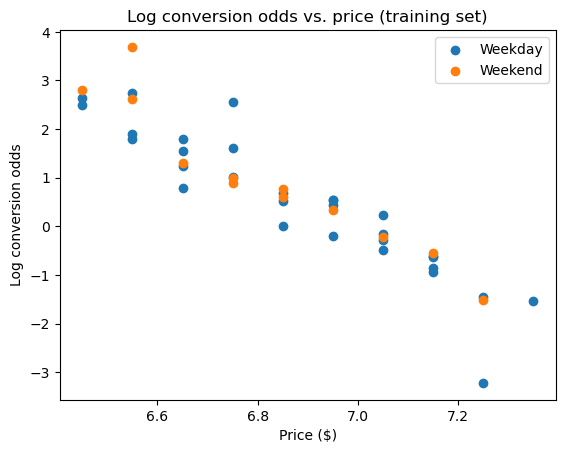

In [30]:
# Creating a new column with the conversion rates
train_set["conversion"] = train_set["sales"] / train_set["potential"]

# Creating a new column with the log-odds of the conversion rates (to make the logit model linear in the parameters)
train_set["log_odds"] = np.log(train_set["conversion"] / (1 - train_set["conversion"]))

# Displaying the first 10 rows of the training set with the new columns for verification
print(train_set.head(10).round(3))

# Plotting log odds against price, separating weekdays and weekends
weekday = train_set[train_set["weekend"] == 0]
weekend = train_set[train_set["weekend"] == 1]

plt.scatter(weekday["price"], weekday["log_odds"], label="Weekday")
plt.scatter(weekend["price"], weekend["log_odds"], label="Weekend")
plt.xlabel("Price ($)")
plt.ylabel("Log conversion odds")
plt.title("Log conversion odds vs. price (training set)")
plt.legend()
plt.show()



In [31]:
print("Logit model with weekend")

# Creating variables for the training set data
X_train = train_set[["price", "weekend"]]
y_train = train_set["log_odds"]

# Fitting a linear regression to the log odds of the conversion rates
logit_model = LinearRegression()
logit_model.fit(X_train, y_train)

# Getting the coefficients of the linear regression
print("Intercept:", logit_model.intercept_)
print("Price coefficient:", logit_model.coef_[0])
print("Weekend coefficient:", logit_model.coef_[1])

# Finding the parameters a, b and c of the logit model
a_logit = logit_model.intercept_
print("a =", a_logit)
b_logit = - logit_model.coef_[0]
print("b =", b_logit)
c_logit = logit_model.coef_[1]
print("c =", c_logit)
print("Weekend odds multiplier:", np.exp(c_logit))

# Finding the R-squared value of the linear regression on the training data (in log-odds space)
r_squared_logit = logit_model.score(X_train, y_train)
print("R-squared:", r_squared_logit)


Logit model with weekend
Intercept: 36.40023694600271
Price coefficient: -5.219411078359142
Weekend coefficient: 0.1574927282347647
a = 36.40023694600271
b = 5.219411078359142
c = 0.1574927282347647
Weekend odds multiplier: 1.170572245824182
R-squared: 0.8639126007137149


**Answer to part (a):**

Fitting the log odds of the conversion rate on the training set (Table 4.2) gives (the statement says "test data", a typo: as in the text, the model is fit on the training set and evaluated on the test set):

| Explanatory variable | Coefficient | Value |
|---|---|---|
| Intercept | $a$ | 36.40 |
| Price | $-b$ | −5.22 ($b = 5.22$) |
| Weekend | $c$ | 0.157 |
| Potential demand | (not estimated) | multiplier: $d = D \cdot \rho(p, w)$ |

So the fitted model is

$$\rho(p, w) = \frac{e^{36.40 - 5.22p + 0.157w}}{1 + e^{36.40 - 5.22p + 0.157w}}, \qquad d(p, w) = D \cdot \rho(p, w)$$

* **Price:** customers are very price-sensitive. Half of the visitors buy at about \$6.97 on weekdays, and around that price a \$0.10 increase cuts sales by about a quarter.
* **Weekend:** weekend odds of conversion are $e^{0.157} \approx 1.17$ times weekday odds. For the same number of visitors, this means only about 1% to 13% higher sales, depending on the price.
* **Potential demand:** it has no estimated coefficient. It enters the model as the multiplier that turns the conversion rate into sales.

Compared with the book's price-only logit ($\hat{a} = 36.67$, $\hat{b} = 5.25$), adding Weekend barely changes the price sensitivity, and the weekend effect is small. Once potential demand is in the model, weekends mostly bring more visitors, not visitors who are more likely to buy.


In [32]:
# Creating variables for the test set data
X_test = test_set[["price", "weekend"]]
y_test = test_set["sales"]
D_test = test_set["potential"]

# Predicting the log odds of the conversion rates for the test set
log_odds_predictions = logit_model.predict(X_test)

# Converting the log odds back to conversion rates with the logistic function
conversion_predictions = np.exp(log_odds_predictions) / (1 + np.exp(log_odds_predictions))

# Multiplying the conversion rates by the potential demand to get the predicted sales
logit_predictions = D_test * conversion_predictions

# Creating a predictions table to compare the actual sales and the predictions from the logit model
predictions_table = pd.DataFrame({
    "day": test_set["day"],
    "price": test_set["price"],
    "weekend": test_set["weekend"],
    "potential": D_test,
    "actual sales": y_test,
    "predicted conversion": conversion_predictions,
    "predicted sales": logit_predictions
})
predictions_table.round(2)


,day,price,weekend,potential,actual sales,predicted conversion,predicted sales
0,1,6.45,1,56,52,0.95,53.06
1,2,6.55,1,55,49,0.91,50.30
2,3,6.65,0,39,34,0.84,32.93
3,4,6.75,0,27,15,0.76,20.60
4,5,6.85,0,27,17,0.66,17.72
5,6,6.95,0,22,17,0.53,11.69
6,7,7.05,0,32,6,0.40,12.87
7,8,7.15,1,66,24,0.32,21.02
8,9,7.25,1,42,15,0.22,9.12
9,10,7.15,0,30,13,0.29,8.56


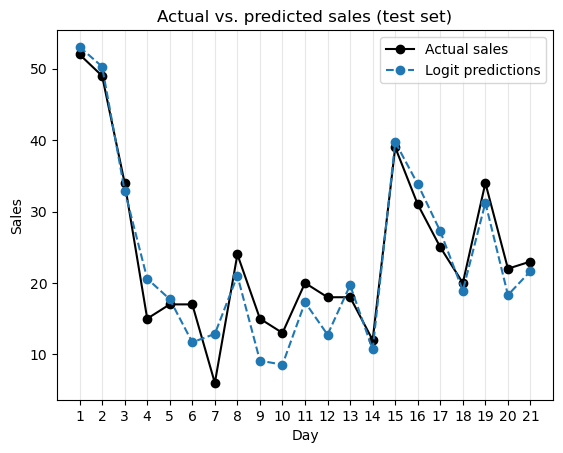

In [33]:
# Plotting actual sales and logit predictions for each day of the test set
plt.plot(test_set["day"], y_test, "o-", color="black", label="Actual sales")
plt.plot(test_set["day"], logit_predictions, "o--", label="Logit predictions")
plt.xticks(test_set["day"])
plt.grid(axis="x", alpha=0.3)
plt.xlabel("Day")
plt.ylabel("Sales")
plt.title("Actual vs. predicted sales (test set)")
plt.legend()
plt.show()


In [34]:
def metrics(predictions):
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mape = mean_absolute_percentage_error(y_test, predictions)
    wmape = np.sum(np.abs(predictions - y_test)) / np.sum(y_test)
    return rmse, mape, wmape

rmse_logit, mape_logit, wmape_logit = metrics(logit_predictions)
print(f"RMSE: {rmse_logit:.2f}, MAPE: {mape_logit:.2f}, Weighted MAPE: {wmape_logit:.2f}")

RMSE: 3.46, MAPE: 0.19, Weighted MAPE: 0.12


**Book's logit model (price only, Section 4.2.2), for comparison:**

In [35]:
logit_model_price = LinearRegression()
logit_model_price.fit(train_set[["price"]], y_train)
print("a =", logit_model_price.intercept_)
print("b =", -logit_model_price.coef_[0])

z = logit_model_price.predict(test_set[["price"]])
logit_price_predictions = D_test * np.exp(z) / (1 + np.exp(z))

rmse_logit_price, mape_logit_price, wmape_logit_price = metrics(logit_price_predictions)
print(f"RMSE: {rmse_logit_price:.2f}, MAPE: {mape_logit_price:.2f}, Weighted MAPE: {wmape_logit_price:.2f}")

a = 36.67052482283974
b = 5.252243063398484
RMSE: 3.57, MAPE: 0.19, Weighted MAPE: 0.12


In [36]:
# Text and Exercise 1 values are the test set results from c4-ex1.ipynb
comparison_table = pd.DataFrame({
    "Model": ["Linear", "Exponential", "Constant-elasticity"] * 2 + ["Logit", "Logit"],
    "Variables": ["Price"] * 3 + ["Price + Weekend"] * 3 + ["Price + Potential", "Price + Weekend + Potential"],
    "RMSE": [9.18, 10.00, 10.00, 6.82, 7.70, 7.73, rmse_logit_price, rmse_logit],
    "MAPE": [0.34, 0.36, 0.36, 0.27, 0.29, 0.29, mape_logit_price, mape_logit],
    "Weighted MAPE": [0.30, 0.35, 0.35, 0.24, 0.27, 0.27, wmape_logit_price, wmape_logit],
})
comparison_table.round(2)

,Model,Variables,RMSE,MAPE,Weighted MAPE
0,Linear,Price,9.18,0.34,0.30
1,Exponential,Price,10.00,0.36,0.35
2,Constant-elasticity,Price,10.00,0.36,0.35
3,Linear,Price + Weekend,6.82,0.27,0.24
4,Exponential,Price + Weekend,7.70,0.29,0.27
5,Constant-elasticity,Price + Weekend,7.73,0.29,0.27
6,Logit,Price + Potential,3.57,0.19,0.12
7,Logit,Price + Weekend + Potential,3.46,0.19,0.12


**Answer to part (b):**

On the test set, the logit model with Price, Weekend and Potential Demand has **RMSE = 3.46, MAPE = 0.19 and weighted MAPE = 0.12** (MAPEs as fractions, as in the book's tables).

* **Compared with the text models** (linear, exponential and constant-elasticity with price only), its RMSE is about a third and its weighted MAPE less than half.
* **Compared with the Exercise 1 models** (with Weekend), it roughly halves RMSE and weighted MAPE, and lowers MAPE by about 30%. The best of them, the linear model, has 6.82 / 0.27 / 0.24.
* **The improvement comes from potential demand, not from Weekend:** the book's price-only logit already reaches 3.57 / 0.19 / 0.12. Adding Weekend only slightly lowers RMSE and leaves MAPE and weighted MAPE unchanged, so Weekend adds little once potential demand is in the model.

(**Note on the book:** for its price-only logit, the book reports RMSE = 4.40, MAPE = .19 and weighted MAPE = .08. The coefficients are reproduced exactly here ($\hat{a} = 36.67$, $\hat{b} = 5.25$), but on the test set the metrics are 3.57 / 0.19 / 0.12, another inconsistency in the book's numbers, like Table 4.6 in Exercise 1.)

### Final commentary

* **Weekend vs. potential demand:** the two are correlated, since weekends bring more visitors. Potential demand carries Weekend's information and much more, so once it is in the model, Weekend adds almost nothing.
* **The logit without potential demand:** the logit can also be used without $D$, with an unknown market size $C$ (Table 3.3). But then the log-odds trick no longer works: $C$, $a$ and $b$ must be estimated with nonlinear least squares, and with so few prices the data cannot pin down $C$ reliably. It is harder to implement and less trustworthy than the models of Exercise 1.
* **Which model to use:** with potential demand, the logit model is clearly the best. Without it, the linear model with Weekend from Exercise 1 is the practical choice.
* **Is potential demand realistic?** Online sellers usually observe it (e.g., Amazon's glance views). Future potential demand is unknown, but the pricing decision does not need it: $D$ multiplies profit without depending on price, so the optimal price is the same at any traffic level. Future $D$ only matters for forecasting sales volume (e.g., inventory), and there Weekend becomes useful again.
* **Limitation:** least squares on log odds (the book's method) weights every day equally; a binomial logistic regression would give more weight to days with more visitors.